# 05 · Filings analyser

Every results release filed with the SEC by the live universe since 2019 (6-K and 8-K exhibits,
HTML and PDF), parsed into a company-quarter table. Each number keeps the sentence it came from,
so any figure can be checked against the filing in one click.

Fields: next-quarter days already fixed and their average rate; realised TCE; fleet size;
dividend per share; net income.

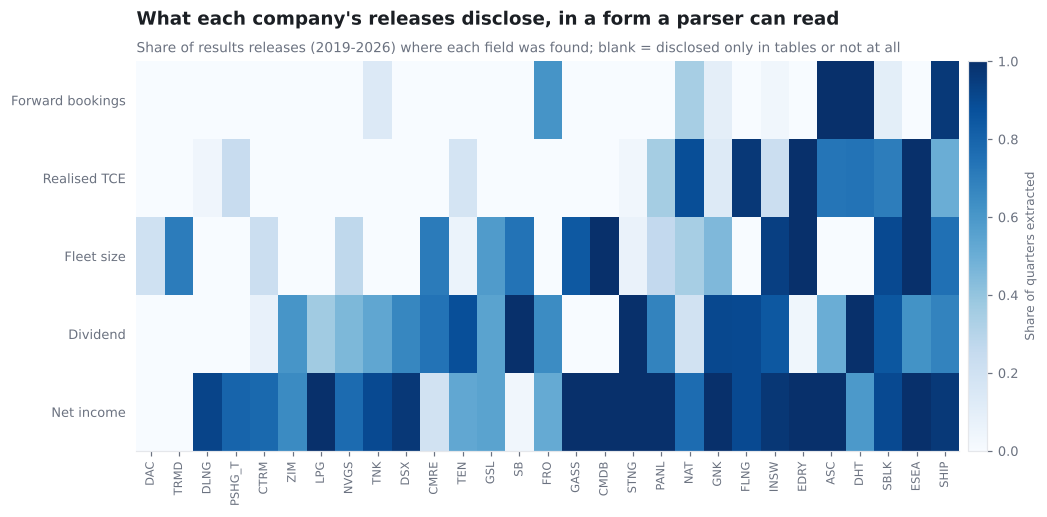

,quarter,forward_pct,forward_rate,tce,booking_surprise,dividend,flags
117,2024Q1,72.0,51000.0,50900.0,0.001965,0.29,dividend raised to $0.29
118,2024Q2,75.0,42100.0,49100.0,-0.142566,0.27,dividend cut to $0.27
119,2024Q4,74.0,36400.0,38800.0,-0.061856,0.17,dividend cut to $0.17
120,2025Q1,72.0,48700.0,38200.0,0.274869,0.15,next-quarter bookings +27% vs this quarter's T...
121,2025Q2,73.0,38500.0,46300.0,-0.168467,0.24,next-quarter bookings -17% vs this quarter's T...
122,2025Q4,76.0,78900.0,60300.0,0.308458,0.41,next-quarter bookings +31% vs this quarter's T...
123,2026Q1,70.0,168300.0,78800.0,1.135787,0.64,next-quarter bookings +114% vs this quarter's ...
124,2026Q2,58.0,152700.0,126700.0,0.205209,1.22,next-quarter bookings +21% vs this quarter's T...


In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, pandas as pd, matplotlib.pyplot as plt
from shiplab import charts, filings
from shiplab.config import DATA
t = filings.table()
charts.filings_coverage(t); plt.show()
x = pd.read_csv(DATA / "results" / "filings_extracted.csv")
x[x.company == "DHT"][["quarter", "forward_pct", "forward_rate", "tce", "booking_surprise", "dividend", "flags"]].tail(8)

**Audit trail.** The sentence behind each extracted forward booking:

In [2]:
pd.set_option("display.max_colwidth", 220)
x.dropna(subset=["forward_rate"]).sample(6, random_state=3)[["company", "quarter", "forward_pct", "forward_rate", "forward_src"]]

,company,quarter,forward_pct,forward_rate,forward_src
110,DHT,2022Q1,69.0,24800.0,"Thus far in the second quarter of 2022, 69% of the available VLCC days have been booked at an average rate of $24,800 per day on a discharge-to-discharge basis (not including any potential profit splits on time chart..."
614,SHIP,2022Q3,72.0,18500.0,"Dollars) Q3 2022 Q3 2021 9M 2022 9M 2021 Interest and finance costs, net (3,933) (4,560) (9,946) (12,867) Add: Amortization of deferred finance charges and other discounts 641 816 1,916 2,692 Add: Amortization of con..."
5,ASC,2020Q2,50.0,13800.0,"As of July 28, 2020, the Company had fixed approximately 50% of its total MR revenue days for the third quarter of 2020 at an average TCE rate of approximately $13,800 per day in line with market conditions but not r..."
103,DHT,2020Q1,66.0,110400.0,"Thus far in the second quarter of 2020, 66% of the available VLCC spot days have been booked at an average rate of $110,400 per day on a discharge to discharge basis (see table I for details)."
285,FRO,2023Q2,74.0,53200.0,"For the third quarter of 2023, we estimate spot TCE on a load-to-discharge basis of $53,200 contracted for 74% of vessel days for VLCCs, $48,800 contracted for 67% of vessel days for Suezmax tankers and $40,500 contr..."
25,ASC,2025Q2,50.0,25450.0,"Based on approximately 50% of total revenue days currently fixed for the third quarter of 2025, the average spot TCE rate is approximately $25,450 per day for MR Eco-Design tankers; based on approximately 65% of reve..."


**Quarter-on-quarter flags**, the first things an analyst checks on results day: bookings far
above or below the quarter just reported, dividend changes, fleet growth or sales, coverage
jumps.

In [3]:
latest = x.sort_values("filed").groupby("company").tail(1)
latest[latest["flags"].fillna("") != ""][["company", "quarter", "filed", "flags"]]

,company,quarter,filed,flags
581,SB,2026Q2,2026-07-29,dividend raised to $0.07
29,ASC,2026Q2,2026-07-29,dividend raised to $0.79
601,SBLK,2026Q2,2026-08-05,dividend raised to $0.90; fleet -3 vessels to 138
124,DHT,2026Q2,2026-08-05,next-quarter bookings +21% vs this quarter's TCE; dividend raised to $1.22
353,GNK,2026Q2,2026-08-05,dividend raised to $0.80
629,SHIP,2026Q2,2026-08-06,dividend raised to $0.35
525,PANL,2026Q2,2026-08-10,dividend raised to $0.10
297,FRO,2026Q2,2026-08-28,dividend raised to $2.61


## Does the booking surprise move the stock?

**Specified before any return was computed:** booking surprise = next-quarter booked rate /
this quarter's realised TCE - 1; expected sign positive; outcome = the stock's return minus its
segment basket over the 20 trading days after the release. Logged in the trials ledger.

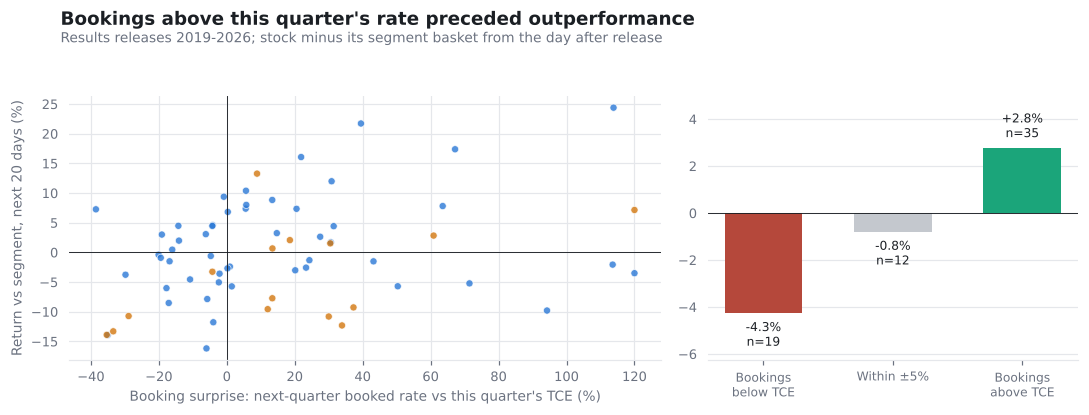

{'releases': 758,
 'companies': 29,
 'quarters': ['2018Q3', '2026Q3'],
 'field_coverage': {'forward_rate': 0.161,
  'tce': 0.28,
  'fleet_size': 0.371,
  'dividend': 0.547,
  'net_income_m': 0.765},
 'events': 66,
 'rank_ic': 0.25977035632128936,
 't_stat': 2.152041530316205,
 'mean_excess_when_surprise_above_5pct': 0.027576391551165407,
 'n_above': 35,
 'mean_excess_when_surprise_below_minus_5pct': -0.042758301195527045,
 'n_below': 19,
 'note': '20 trading days after release, return minus segment basket; pre-specified sign positive'}

In [4]:
ev = pd.read_csv(DATA / "results" / "filings_event_study.csv")
charts.filings_event(ev); plt.show()
json.load(open(DATA / "results" / "filings_summary.json"))

**Reading.** The rank correlation is about 0.26 (t about 2.2) over 66 releases: when bookings
run above the quarter just reported, the stock beat its segment by about 3% over the next
month; when they run below, it lagged by about 4%. The market under-reacts to guidance that is
in plain text on results day. The sample is small, mostly tankers, and the test was not
committed to git in advance, so it is a lead to track live, not a proven edge.